# ANN 2: Entity Embeddings (Multi-Input ANN)
Each categorical column gets its own Embedding layer. The numeric columns go in as one input.

Main idea: instead of one-hot encoding, each categorical column gets its own Embedding layer. The model learns a small vector for every category and categories that behave similarly end up close to each other.

# Import Libraries

In [29]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(42)
os.makedirs("weights", exist_ok=True)

# Load the Dataset

In [30]:
from google.colab import files
files.upload()

Saving bank_clean.csv to bank_clean.csv


{'bank_clean.csv': b'age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted\n56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0\n57,services,married,high.school,unknown,no,no,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0\n37,services,married,high.school,no,yes,no,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0\n40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0\n56,services,married,high.school,no,no,yes,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0\n45,services,married,basic.9y,unknown,no,no,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0\n59,admin.,married,professional.course,no,no,no,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.85

In [31]:
df = pd.read_csv("bank_clean.csv")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0


In [32]:
cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]
num_cols = ["age", "campaign", "pdays", "previous", "emp.var.rate", "cons.price.idx",
            "cons.conf.idx", "euribor3m", "nr.employed", "previously_contacted"]

# Train / Validation / Test Split

In [33]:
train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df["y"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["y"], random_state=42)

y_train = train_df["y"].values
y_val = val_df["y"].values
y_test = test_df["y"].values

print(len(train_df), len(val_df), len(test_df))

28823 6176 6177


# Prepare the Inputs

 Scaling numeric columns

In [34]:
category_ids = {}
for col in cat_cols:
    categories = sorted(train_df[col].unique())
    category_ids[col] = {cat: i + 1 for i, cat in enumerate(categories)}   # 0 = unseen category

scaler = StandardScaler()
scaler.fit(train_df[num_cols])

def make_inputs(data):
    inputs = {}
    for col in cat_cols:
        inputs[col] = data[col].map(category_ids[col]).fillna(0).values
    inputs["numeric"] = scaler.transform(data[num_cols])
    return inputs

x_train = make_inputs(train_df)
x_val = make_inputs(val_df)
x_test = make_inputs(test_df)

In [35]:
# we give the "yes" class a bigger weight
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
class_weight = {0: len(y_train) / (2 * neg), 1: len(y_train) / (2 * pos)}
class_weight

{0: np.float64(0.563477478886456), 1: np.float64(4.438404681244226)}

Accuracy alone is misleading, so we also look at AUC and recall.

# Embedding Inputs

In [36]:
def embedding_inputs(emb_size):
    inputs = []
    outputs = []
    for col in cat_cols:
        n_categories = len(category_ids[col]) + 1
        inp = keras.Input(shape=(1,), name=col)
        emb = layers.Embedding(n_categories, emb_size, name="emb_" + col)(inp)
        inputs.append(inp)
        outputs.append(layers.Flatten()(emb))

    num_inp = keras.Input(shape=(len(num_cols),), name="numeric")
    inputs.append(num_inp)
    outputs.append(num_inp)

    x = layers.Concatenate()(outputs)
    return inputs, x

# Baseline Model

In [37]:
def build_baseline_model(emb_size=4, optimizer="adam"):
    inputs, x = embedding_inputs(emb_size)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dense(32, activation="relu")(x)
    output = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, output)
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(curve="PR", name="auc"), keras.metrics.Recall(name="recall")]
    )
    return model

baseline_model = build_baseline_model()
baseline_model.summary()

Model: "functional_28"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ job (InputLayer)    │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ marital             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ education           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ default             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ housing             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ loan (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ contact             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ month (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ day_of_week         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ poutcome            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_job (Embedding) │ (None, 1, 4)      │         52 │ job[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_marital         │ (None, 1, 4)      │         20 │ marital[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_education       │ (None, 1, 4)      │         36 │ education[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_default         │ (None, 1, 4)      │         16 │ default[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_housing         │ (None, 1, 4)      │         16 │ housing[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_loan            │ (None, 1, 4)      │         16 │ loan[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_contact         │ (None, 1, 4)      │         12 │ contact[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_month           │ (None, 1, 4)      │         44 │ month[0][0]       │
│ (Embedding)         │                   │            │                 

 Total params: 5,629 (21.99 KB)

 Trainable params: 5,629 (21.99 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
history = baseline_model.fit(x_train, y_train, epochs=20, batch_size=256,
                             validation_data=(x_val, y_val), class_weight=class_weight)
baseline_model.save_weights("weights/ann2_baseline.weights.h5")

Epoch 1/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.7176 - auc: 0.3903 - loss: 0.5734 - recall: 0.6859 - val_accuracy: 0.8055 - val_auc: 0.4452 - val_loss: 0.5187 - val_recall: 0.6494
Epoch 2/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8148 - auc: 0.4363 - loss: 0.5449 - recall: 0.6277 - val_accuracy: 0.8237 - val_auc: 0.4482 - val_loss: 0.5133 - val_recall: 0.6307
Epoch 3/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8234 - auc: 0.4434 - loss: 0.5397 - recall: 0.6233 - val_accuracy: 0.8256 - val_auc: 0.4517 - val_loss: 0.5115 - val_recall: 0.6307
Epoch 4/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8274 - auc: 0.4489 - loss: 0.5365 - recall: 0.6255 - val_accuracy: 0.8298 - val_auc: 0.4515 - val_loss: 0.5082 - val_recall: 0.6422
Epoch 5/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8291 - auc: 0.4539 - loss: 0.5342 - recall: 0.6273 - val_accuracy: 0.8332 - val_auc: 0.4538 - val_loss: 0.5040 - val_recall: 0.6394
Epoch 6/2

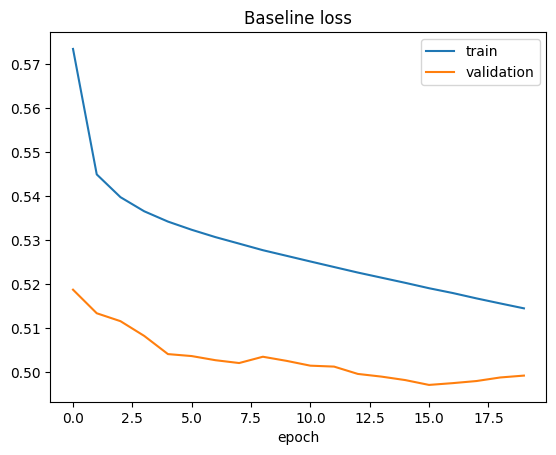

In [39]:
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Baseline loss")
plt.xlabel("epoch")
plt.legend()
plt.show()

Validation loss is lower than train loss because the class weights are only added to the train loss.

# Optimizers

In [40]:
optimizers = {
    "SGD": keras.optimizers.SGD(learning_rate=0.01),
    "SGD Momentum": keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "Adam": keras.optimizers.Adam(learning_rate=0.001)
}

for name, opt in optimizers.items():
    model = build_baseline_model(optimizer=opt)
    model.fit(x_train, y_train, epochs=20, batch_size=256, class_weight=class_weight, verbose=0)
    loss, acc, auc, recall = model.evaluate(x_val, y_val, verbose=0)
    print(f"{name}: accuracy={acc:.4f}  AUC={auc:.4f}  recall={recall:.4f}")
    model.save_weights(f"weights/ann2_opt_{name.replace(' ', '_')}.weights.h5")

SGD: accuracy=0.7898  AUC=0.4475  recall=0.6767
SGD Momentum: accuracy=0.8308  AUC=0.4501  recall=0.6379
Adam: accuracy=0.8311  AUC=0.4566  recall=0.6365


# L2 Regularization

In [41]:
def build_l2_model(emb_size=4, l2=0.001):
    inputs, x = embedding_inputs(emb_size)
    x = layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(l2))(x)
    output = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, output)
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(curve="PR", name="auc"), keras.metrics.Recall(name="recall")]
    )
    return model

l2_model = build_l2_model()
history_l2 = l2_model.fit(x_train, y_train, epochs=20, batch_size=256,
                          validation_data=(x_val, y_val), class_weight=class_weight)
l2_model.save_weights("weights/ann2_l2.weights.h5")

Epoch 1/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.7422 - auc: 0.3958 - loss: 0.6388 - recall: 0.6852 - val_accuracy: 0.7919 - val_auc: 0.4364 - val_loss: 0.5811 - val_recall: 0.6710
Epoch 2/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8081 - auc: 0.4328 - loss: 0.5900 - recall: 0.6347 - val_accuracy: 0.8248 - val_auc: 0.4434 - val_loss: 0.5590 - val_recall: 0.6408
Epoch 3/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8216 - auc: 0.4407 - loss: 0.5751 - recall: 0.6193 - val_accuracy: 0.8261 - val_auc: 0.4463 - val_loss: 0.5491 - val_recall: 0.6351
Epoch 4/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8240 - auc: 0.4440 - loss: 0.5676 - recall: 0.6206 - val_accuracy: 0.8279 - val_auc: 0.4464 - val_loss: 0.5420 - val_recall: 0.6365
Epoch 5/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8259 - auc: 0.4450 - loss: 0.5626 - recall: 0.6233 - val_accuracy: 0.8277 - val_auc: 0.4475 - val_loss: 0.5364 - val_recall: 0.6336
Epoch 6/2

# Dropout Regularization

In [42]:
def build_dropout_model(emb_size=4, rate=0.3):
    inputs, x = embedding_inputs(emb_size)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(rate)(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(rate)(x)
    output = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, output)
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(curve="PR", name="auc"), keras.metrics.Recall(name="recall")]
    )
    return model

dropout_model = build_dropout_model()
history_dropout = dropout_model.fit(x_train, y_train, epochs=20, batch_size=256,
                                    validation_data=(x_val, y_val), class_weight=class_weight)
dropout_model.save_weights("weights/ann2_dropout.weights.h5")

Epoch 1/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.6789 - auc: 0.3436 - loss: 0.6018 - recall: 0.6695 - val_accuracy: 0.7642 - val_auc: 0.4320 - val_loss: 0.5485 - val_recall: 0.6911
Epoch 2/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7815 - auc: 0.4002 - loss: 0.5656 - recall: 0.6415 - val_accuracy: 0.7986 - val_auc: 0.4410 - val_loss: 0.5327 - val_recall: 0.6624
Epoch 3/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8089 - auc: 0.4096 - loss: 0.5582 - recall: 0.6270 - val_accuracy: 0.8211 - val_auc: 0.4425 - val_loss: 0.5220 - val_recall: 0.6394
Epoch 4/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8247 - auc: 0.4208 - loss: 0.5495 - recall: 0.6169 - val_accuracy: 0.8196 - val_auc: 0.4433 - val_loss: 0.5272 - val_recall: 0.6422
Epoch 5/20
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8291 - auc: 0.4188 - loss: 0.5494 - recall: 0.6153 - val_accuracy: 0.8204 - val_auc: 0.4420 - val_loss: 0.5271 - val_recall: 0.6422
Epoch 6

# Early Stopping

In [43]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

es_model = build_baseline_model()
history_es = es_model.fit(x_train, y_train, epochs=50, batch_size=256,
                          validation_data=(x_val, y_val), class_weight=class_weight,
                          callbacks=[early_stop])
es_model.save_weights("weights/ann2_early_stopping.weights.h5")

Epoch 1/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7180 - auc: 0.3829 - loss: 0.5756 - recall: 0.6720 - val_accuracy: 0.7770 - val_auc: 0.4425 - val_loss: 0.5299 - val_recall: 0.6767
Epoch 2/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8010 - auc: 0.4311 - loss: 0.5472 - recall: 0.6406 - val_accuracy: 0.8230 - val_auc: 0.4496 - val_loss: 0.5156 - val_recall: 0.6336
Epoch 3/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8251 - auc: 0.4420 - loss: 0.5404 - recall: 0.6178 - val_accuracy: 0.8290 - val_auc: 0.4529 - val_loss: 0.5104 - val_recall: 0.6279
Epoch 4/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8284 - auc: 0.4484 - loss: 0.5370 - recall: 0.6181 - val_accuracy: 0.8303 - val_auc: 0.4511 - val_loss: 0.5070 - val_recall: 0.6293
Epoch 5/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8296 - auc: 0.4520 - loss: 0.5348 - recall: 0.6230 - val_accuracy: 0.8303 - val_auc: 0.4518 - val_loss: 0.5067 - val_recall: 0.6336
Epoch 6/5

# Compare the Loss Curves

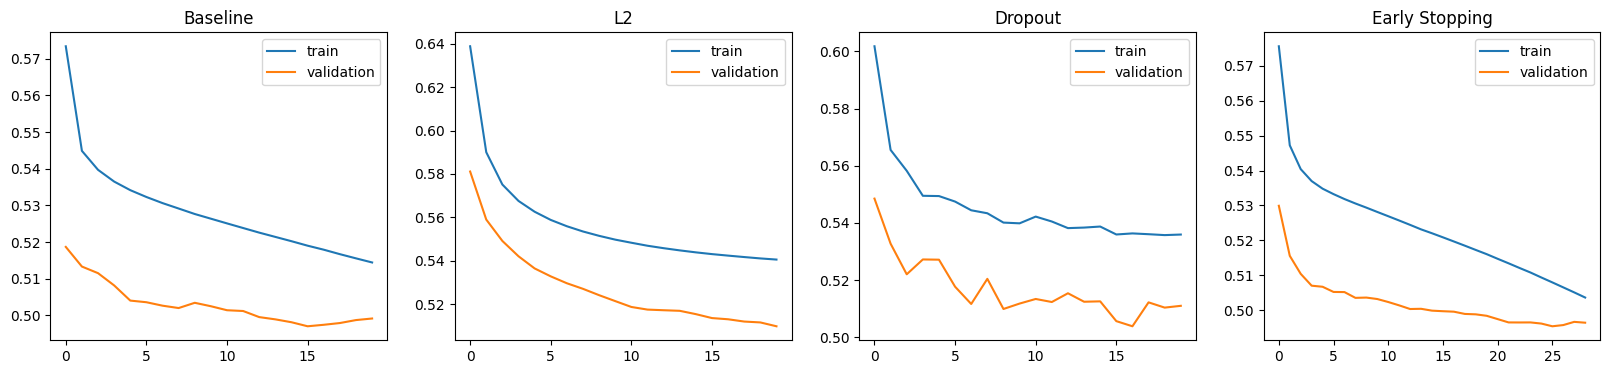

In [44]:
all_histories = {"Baseline": history, "L2": history_l2, "Dropout": history_dropout, "Early Stopping": history_es}

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, h) in zip(axes, all_histories.items()):
    ax.plot(h.history["loss"], label="train")
    ax.plot(h.history["val_loss"], label="validation")
    ax.set_title(name)
    ax.legend()
plt.show()

In [45]:
for name, model in [("Baseline", baseline_model), ("L2", l2_model), ("Dropout", dropout_model), ("Early Stopping", es_model)]:
    loss, acc, auc, recall = model.evaluate(x_val, y_val, verbose=0)
    print(f"{name}: accuracy={acc:.4f}  AUC={auc:.4f}  recall={recall:.4f}")

Baseline: accuracy=0.8344  AUC=0.4550  recall=0.6379
L2: accuracy=0.8369  AUC=0.4540  recall=0.6437
Dropout: accuracy=0.8340  AUC=0.4562  recall=0.6422
Early Stopping: accuracy=0.8384  AUC=0.4609  recall=0.6422


# Hyperparameter Tuning

### Embedding size

In [46]:
emb_sizes = [2, 4, 8, 16]

for size in emb_sizes:
    model = build_baseline_model(emb_size=size)
    model.fit(x_train, y_train, epochs=20, batch_size=256, class_weight=class_weight, verbose=0)
    loss, acc, auc, recall = model.evaluate(x_val, y_val, verbose=0)
    print(f"Embedding size {size} → accuracy={acc:.4f}  AUC={auc:.4f}  recall={recall:.4f}")
    model.save_weights(f"weights/ann2_emb_{size}.weights.h5")

Embedding size 2 → accuracy=0.8344  AUC=0.4530  recall=0.6422
Embedding size 4 → accuracy=0.8355  AUC=0.4567  recall=0.6379
Embedding size 8 → accuracy=0.8386  AUC=0.4543  recall=0.6351
Embedding size 16 → accuracy=0.8274  AUC=0.4566  recall=0.6379


### Learning rate

In [47]:
learning_rates = [0.01, 0.001, 0.0001]

for lr in learning_rates:
    model = build_baseline_model(optimizer=keras.optimizers.Adam(learning_rate=lr))
    model.fit(x_train, y_train, epochs=20, batch_size=256, class_weight=class_weight, verbose=0)
    loss, acc, auc, recall = model.evaluate(x_val, y_val, verbose=0)
    print(f"LR {lr} → accuracy={acc:.4f}  AUC={auc:.4f}  recall={recall:.4f}")
    model.save_weights(f"weights/ann2_lr_{lr}.weights.h5")

LR 0.01 → accuracy=0.7801  AUC=0.4016  recall=0.6652
LR 0.001 → accuracy=0.8391  AUC=0.4583  recall=0.6365
LR 0.0001 → accuracy=0.8256  AUC=0.4485  recall=0.6365


### Batch size

In [48]:
batch_sizes = [64, 128, 256, 512]

for bs in batch_sizes:
    model = build_baseline_model()
    model.fit(x_train, y_train, epochs=20, batch_size=bs, class_weight=class_weight, verbose=0)
    loss, acc, auc, recall = model.evaluate(x_val, y_val, verbose=0)
    print(f"Batch size {bs} → accuracy={acc:.4f}  AUC={auc:.4f}  recall={recall:.4f}")
    model.save_weights(f"weights/ann2_batch_{bs}.weights.h5")

Batch size 64 → accuracy=0.8344  AUC=0.4602  recall=0.6379
Batch size 128 → accuracy=0.8340  AUC=0.4544  recall=0.6336
Batch size 256 → accuracy=0.8352  AUC=0.4533  recall=0.6365
Batch size 512 → accuracy=0.8300  AUC=0.4602  recall=0.6537


### Dropout rates

In [49]:
for rate in [0.2, 0.5, 0.8]:
    model = build_dropout_model(rate=rate)
    model.fit(x_train, y_train, epochs=20, batch_size=256, class_weight=class_weight, verbose=0)
    loss, acc, auc, recall = model.evaluate(x_val, y_val, verbose=0)
    print(f"Dropout {rate} → accuracy={acc:.4f}  AUC={auc:.4f}  recall={recall:.4f}")
    model.save_weights(f"weights/ann2_dropout_{rate}.weights.h5")

Dropout 0.2 → accuracy=0.8387  AUC=0.4530  recall=0.6422
Dropout 0.5 → accuracy=0.8313  AUC=0.4503  recall=0.6451
Dropout 0.8 → accuracy=0.8436  AUC=0.4526  recall=0.6106


### L2 values

In [50]:
for l2 in [0.0001, 0.001, 0.01]:
    model = build_l2_model(l2=l2)
    model.fit(x_train, y_train, epochs=20, batch_size=256, class_weight=class_weight, verbose=0)
    loss, acc, auc, recall = model.evaluate(x_val, y_val, verbose=0)
    print(f"L2 {l2} → accuracy={acc:.4f}  AUC={auc:.4f}  recall={recall:.4f}")
    model.save_weights(f"weights/ann2_l2_{l2}.weights.h5")

L2 0.0001 → accuracy=0.8402  AUC=0.4571  recall=0.6379
L2 0.001 → accuracy=0.8387  AUC=0.4529  recall=0.6451
L2 0.01 → accuracy=0.8093  AUC=0.4398  recall=0.6451


# K-Fold Cross-Validation

In [51]:
from sklearn.model_selection import StratifiedKFold

kfold = StratifiedKFold(3, shuffle=True, random_state=42)
scores = []

for train_idx, val_idx in kfold.split(train_df, y_train):
    x_tr = make_inputs(train_df.iloc[train_idx])
    x_v = make_inputs(train_df.iloc[val_idx])

    model = build_baseline_model()
    model.fit(x_tr, y_train[train_idx], epochs=20, batch_size=256, class_weight=class_weight, verbose=0)
    loss, acc, auc, recall = model.evaluate(x_v, y_train[val_idx], verbose=0)
    scores.append(auc)

print("AUC per fold:", np.round(scores, 4))
print("Average CV AUC:", np.mean(scores))

AUC per fold: [0.4422 0.4356 0.4618]
Average CV AUC: 0.446541706720988


# Final Model: L2 + Dropout + Early Stopping

In [52]:
def build_final_model(emb_size=4, l2=0.0001, rate=0.3, lr=0.001):
    inputs, x = embedding_inputs(emb_size)
    x = layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.Dropout(rate)(x)
    x = layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.Dropout(rate)(x)
    output = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, output)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(curve="PR", name="auc"), keras.metrics.Recall(name="recall")]
    )
    return model

final_model = build_final_model()

early_stop_final = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history_final = final_model.fit(x_train, y_train, epochs=50, batch_size=256,
                                validation_data=(x_val, y_val), class_weight=class_weight,
                                callbacks=[early_stop_final])

Epoch 1/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.7096 - auc: 0.3607 - loss: 0.6025 - recall: 0.6560 - val_accuracy: 0.7597 - val_auc: 0.4424 - val_loss: 0.5525 - val_recall: 0.6954
Epoch 2/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7823 - auc: 0.4028 - loss: 0.5722 - recall: 0.6394 - val_accuracy: 0.7882 - val_auc: 0.4470 - val_loss: 0.5438 - val_recall: 0.6739
Epoch 3/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8055 - auc: 0.4104 - loss: 0.5662 - recall: 0.6310 - val_accuracy: 0.8232 - val_auc: 0.4510 - val_loss: 0.5338 - val_recall: 0.6379
Epoch 4/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8219 - auc: 0.4146 - loss: 0.5582 - recall: 0.6230 - val_accuracy: 0.8305 - val_auc: 0.4557 - val_loss: 0.5270 - val_recall: 0.6322
Epoch 5/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8242 - auc: 0.4215 - loss: 0.5553 - recall: 0.6193 - val_accuracy: 0.8280 - val_auc: 0.4545 - val_loss: 0.5213 - val_recall: 0.6336
Epoch 6/

# Evaluate on the Test Set

In [53]:
test_loss, test_acc, test_auc, test_recall = final_model.evaluate(x_test, y_test)
print("Test Accuracy:", test_acc)
print("Test AUC:", test_auc)
print("Test Recall:", test_recall)

194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8511 - auc: 0.4805 - loss: 0.4976 - recall: 0.6537
Test Accuracy: 0.8510603904724121
Test AUC: 0.4805419147014618
Test Recall: 0.6537356376647949


194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
              precision    recall  f1-score   support

          no       0.95      0.88      0.91      5481
         yes       0.40      0.65      0.50       696

    accuracy                           0.85      6177
   macro avg       0.68      0.76      0.70      6177
weighted avg       0.89      0.85      0.87      6177



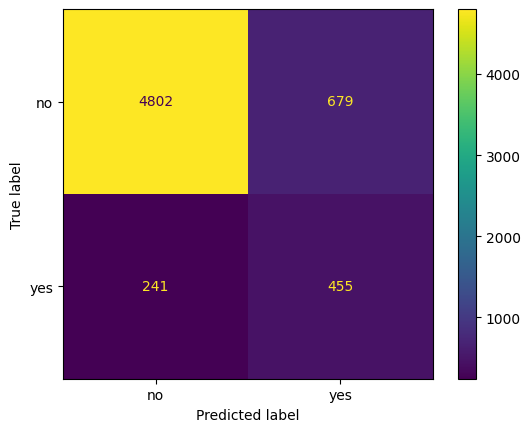

In [54]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_pred = (final_model.predict(x_test) > 0.5).astype(int)
print(classification_report(y_test, y_pred, target_names=["no", "yes"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["no", "yes"])
plt.show()

# Learned Job Embeddings (2D)

Each job is now a vector. We use PCA to draw it in 2D. Jobs close together are treated as similar by the model.

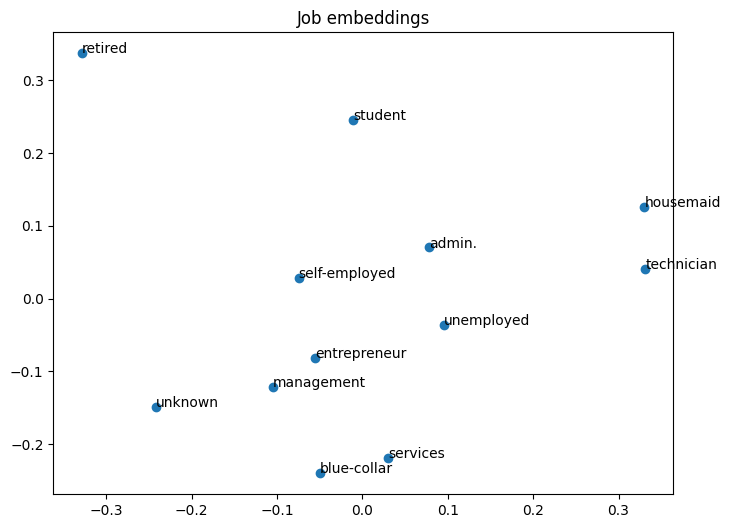

In [55]:
from sklearn.decomposition import PCA

job_layer = final_model.get_layer("emb_job")
job_vectors = job_layer.get_weights()[0][1:]       # skip row 0 (unseen category)
job_names = list(category_ids["job"].keys())

points = PCA(n_components=2).fit_transform(job_vectors)

plt.figure(figsize=(8, 6))
plt.scatter(points[:, 0], points[:, 1])
for (x, y), name in zip(points, job_names):
    plt.annotate(name, (x, y))
plt.title("Job embeddings")
plt.show()

Retired and student (highest subscription rates) are at the top, while blue-collar and services (lowest rates) are close together at the bottom. This shows the embeddings learned meaningful relationships between jobs from the data alone, something one-hot encoding cannot show.

# Save the Final Model

In [56]:
final_model.save_weights("weights/ann2_final.weights.h5")
final_model.save("ann2_final_model.h5")
os.listdir("weights")

['ann2_emb_16.weights.h5',
 'ann2_emb_8.weights.h5',
 'ann2_batch_256.weights.h5',
 'ann2_l2_0.0001.weights.h5',
 'ann2_batch_512.weights.h5',
 'ann2_dropout.weights.h5',
 'ann2_lr_0.0001.weights.h5',
 'ann2_final.weights.h5',
 'ann2_opt_Adam.weights.h5',
 'ann2_l2_0.001.weights.h5',
 'ann2_opt_SGD_Momentum.weights.h5',
 'ann2_lr_0.01.weights.h5',
 'ann2_batch_128.weights.h5',
 'ann2_emb_2.weights.h5',
 'ann2_batch_64.weights.h5',
 'ann2_l2_0.01.weights.h5',
 'ann2_dropout_0.8.weights.h5',
 'ann2_opt_SGD.weights.h5',
 'ann2_baseline.weights.h5',
 'ann2_l2.weights.h5',
 'ann2_dropout_0.5.weights.h5',
 'ann2_dropout_0.2.weights.h5',
 'ann2_lr_0.001.weights.h5',
 'ann2_emb_4.weights.h5',
 'ann2_early_stopping.weights.h5']

# Insights
- Adam worked best (AUC 0.457). Plain SGD was the weakest.
- Early Stopping helped the most. L2 and Dropout made only small changes. Using all three together gave the best model.
- Size 4 was best. Bigger sizes didn’t help, because most columns only have a few categories.
- Accuracy 85%, AUC 0.48, recall 65%. The model found 65% of the clients who subscribed.
- Jobs that subscribe a lot (retired, student) ended up together. Jobs that subscribe less (blue-collar, services) ended up together too. The model learned this by itself.
